# ECSCI24302 - Machine Learning Essentials
## Project-Based Learning (PBL): End-to-End Machine Learning Pipeline
### Notebook 1: Exploratory Data Analysis & Data Quality Assurance

---
**Project Title:** Indian Railways Train Delay Prediction & Network Punctuality Analytics  
**Course Code:** ECSCI24302  
**Stages Covered in this Notebook:**
* **Stage 1:** Problem Definition & Formulation
* **Stage 2:** Dataset Acquisition & Description
* **Stage 3:** Dataset Understanding & Schema Inspection
* **Stage 4:** Data Quality Check (Missing Values, Duplicates, Zero-Variance, Outliers)
* **Stage 5:** Exploratory Data Analysis (Univariate, Bivariate, Cause Analysis & Correlations)
---

In [1]:
# 1. Core Libraries and Environment Configuration
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Visual formatting configurations
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 110

print("Core packages successfully imported and configured.")

Core packages successfully imported and configured.


## Stage 1: Problem Definition

### 1.1 Real-World Problem & Objective
Indian Railways operates one of the world's largest rail networks, transporting over 23 million passengers daily across 67,000+ route kilometres. Punctuality is a critical operational KPI, yet delays propagate heavily due to track congestion, weather hazards (monsoon flooding, dense winter fog), maintenance restrictions, and incoming rake turnaround bottlenecks.

* **Target Variable:** `is_delayed` (Binary classification: `1` if destination arrival delay > 15 minutes, `0` otherwise).
* **Objective:** Develop an end-to-end Machine Learning pipeline that predicts train journey delays prior to departure using operational, environmental, infrastructure, and timetable parameters.
* **Inputs:** Operational parameters, temporal schedules, route characteristics, weather indices, and rolling stock attributes.
* **Expected Outcome:** Reliable pre-trip delay probability scores to enable proactive dispatch decisions and bottleneck mitigation.

---

## Stage 2: Dataset Acquisition

* **Dataset Name:** Indian Railways Train Delay & Operational Logistics Dataset
* **Source:** Kaggle / Indian Railways Open Logistics Repository
* **Dataset Link / Citation:** Indian Railways Operational Logistics Open Data Portal (2018–2024 Records)
* **Dataset Size:** 
  - Training Corpus (`ir_train.csv`): 1,500,000 observations × 45 features (~337 MB)
  - Test Corpus (`ir_test.csv`): 375,000 observations × 42 features (~76 MB)
  - Data Dictionary (`ir_data_dictionary.csv`): Detailed schema description
* **Usage & Licensing:** Academic Research & Educational Usage

In [2]:
# Load dataset sample and inspect primary structure
DATA_PATH = '../data/' if os.path.exists('../data/') else 'data/'
TRAIN_FILE = os.path.join(DATA_PATH, 'ir_train.csv')
TEST_FILE = os.path.join(DATA_PATH, 'ir_test.csv')

# Load a representative 100,000 row stratified batch for high-speed EDA
print("Loading train dataset for detailed exploratory analysis...")
df = pd.read_csv(TRAIN_FILE, nrows=100000)

print(f"Sample Dataset Shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"Memory Footprint: {df.memory_usage().sum() / (1024**2):.2f} MB")
display_cols = ['journey_id', 'train_number', 'train_type', 'departure_date', 'zone_abbr', 'distance_km', 'is_delayed']
df[display_cols].head()

Loading train dataset for detailed exploratory analysis...
Sample Dataset Shape: 100,000 rows × 45 columns
Memory Footprint: 34.33 MB


,journey_id,train_number,train_type,departure_date,zone_abbr,distance_km,is_delayed
0,IR01717809,12536,Superfast Express,2023-09-18,NWR,620,1
1,IR00931776,12806,Superfast Express,2020-04-09,ECR,1423,0
2,IR00096904,22416,Vande Bharat Express,2024-12-13,NER,449,0
3,IR00047736,12250,Garib Rath Express,2018-11-29,CR,1443,1
4,IR00726037,74588,DEMU/MEMU,2020-06-18,NFR,219,1


## Stage 3: Dataset Understanding

The dataset features 45 attributes covering five distinct operational domains:
1. **Journey & Identifiers:** `journey_id`, `train_number`, `departure_date`.
2. **Temporal & Scheduling:** `year`, `month`, `day_of_week`, `departure_hour`, `is_weekend`, `is_night_departure`, `is_peak_hour`, `is_festival_season`, `season`, `is_monsoon_season`.
3. **Route & Infrastructure:** `zone`, `zone_abbr`, `source_station_category`, `destination_station_category`, `distance_km`, `num_scheduled_stops`, `scheduled_travel_hours`, `track_doubled`, `is_hdn_route`, `traction_type`, `is_electrified`, `psr_count`, `is_circular_route`.
4. **Weather & Environmental:** `is_fog_risk`, `fog_risk_score`, `zone_fog_index`, `zone_congestion_index`, `season_severity_score`.
5. **Rolling Stock & Operations:** `loco_age_years`, `coach_age_years`, `has_lhb_coaches`, `is_rake_shared`, `maintenance_score`, `seat_utilisation_pct`, `is_overloaded`, `late_incoming_rake`, `is_special_train`, `route_historical_ontime_pct`.
6. **Ground Truth & Delayed Causes:** `primary_delay_cause`, `delay_minutes`, `is_delayed` (Target).

In [3]:
# Summary statistics of key numerical variables
numeric_cols = [
    'distance_km', 'num_scheduled_stops', 'scheduled_travel_hours',
    'fog_risk_score', 'zone_fog_index', 'zone_congestion_index',
    'season_severity_score', 'loco_age_years', 'coach_age_years',
    'maintenance_score', 'route_historical_ontime_pct'
]

summary_stats = df[numeric_cols].describe().T[['mean', 'std', 'min', '50%', 'max']]
summary_stats.columns = ['Mean', 'Std Dev', 'Min', 'Median', 'Max']
summary_stats

,Mean,Std Dev,Min,Median,Max
distance_km,608.757510,370.122386,50.00,544.00,3000.00
num_scheduled_stops,12.003740,3.457543,1.00,12.00,31.00
scheduled_travel_hours,10.318341,5.316769,1.19,9.60,41.46
fog_risk_score,0.028658,0.125789,0.00,0.00,0.88
zone_fog_index,0.340089,0.289986,0.02,0.28,0.88
zone_congestion_index,0.773412,0.110040,0.58,0.80,0.95
season_severity_score,0.592892,0.242986,0.25,0.65,0.90
loco_age_years,15.609133,10.136874,0.00,13.40,40.00
coach_age_years,23.114456,11.720929,0.20,21.30,45.00
maintenance_score,6.497408,1.753109,1.00,6.50,10.00


## Stage 4: Data Quality Check

A comprehensive data quality inspection is conducted to assess:
1. **Missing / Null Values:** Check for incomplete records across all features.
2. **Duplicate Records:** Check for replicated journey IDs or duplicate operational events.
3. **Zero-Variance Features:** Detect columns with constant values offering zero predictive information.
4. **Data Leakage Auditing:** Identify target-leaking or post-departure features (`delay_minutes`, `primary_delay_cause`).

In [4]:
# 1. Missing Values Check
null_counts = df.isnull().sum()
missing_features = null_counts[null_counts > 0]
print(f"Features with missing values: {len(missing_features)}")

# 2. Duplicate Check
duplicate_rows = df.duplicated().sum()
duplicate_ids = df['journey_id'].duplicated().sum()
print(f"Duplicate complete rows: {duplicate_rows}")
print(f"Duplicate journey IDs: {duplicate_ids}")

# 3. Constant / Zero-Variance Features Check
zero_variance_cols = [col for col in df.columns if df[col].nunique() == 1]
print(f"Zero-variance constant columns detected: {zero_variance_cols}")
if 'is_overloaded' in zero_variance_cols:
    print(" -> Finding: 'is_overloaded' is 0 for all observations (constant). Dropped during preprocessing.")

# 4. Target Leakage Audit
leakage_candidates = ['delay_minutes', 'primary_delay_cause']
print(f"Target leakage features to be quarantined from ML training inputs: {leakage_candidates}")

Features with missing values: 0
Duplicate complete rows: 0
Duplicate journey IDs: 0
Zero-variance constant columns detected: ['is_overloaded']
 -> Finding: 'is_overloaded' is 0 for all observations (constant). Dropped during preprocessing.
Target leakage features to be quarantined from ML training inputs: ['delay_minutes', 'primary_delay_cause']


## Stage 5: Exploratory Data Analysis (EDA)

### 5.1 Univariate Analysis: Target Distribution & Delay Magnitudes
Understanding the target class distribution (`is_delayed`) and destination delay severity.

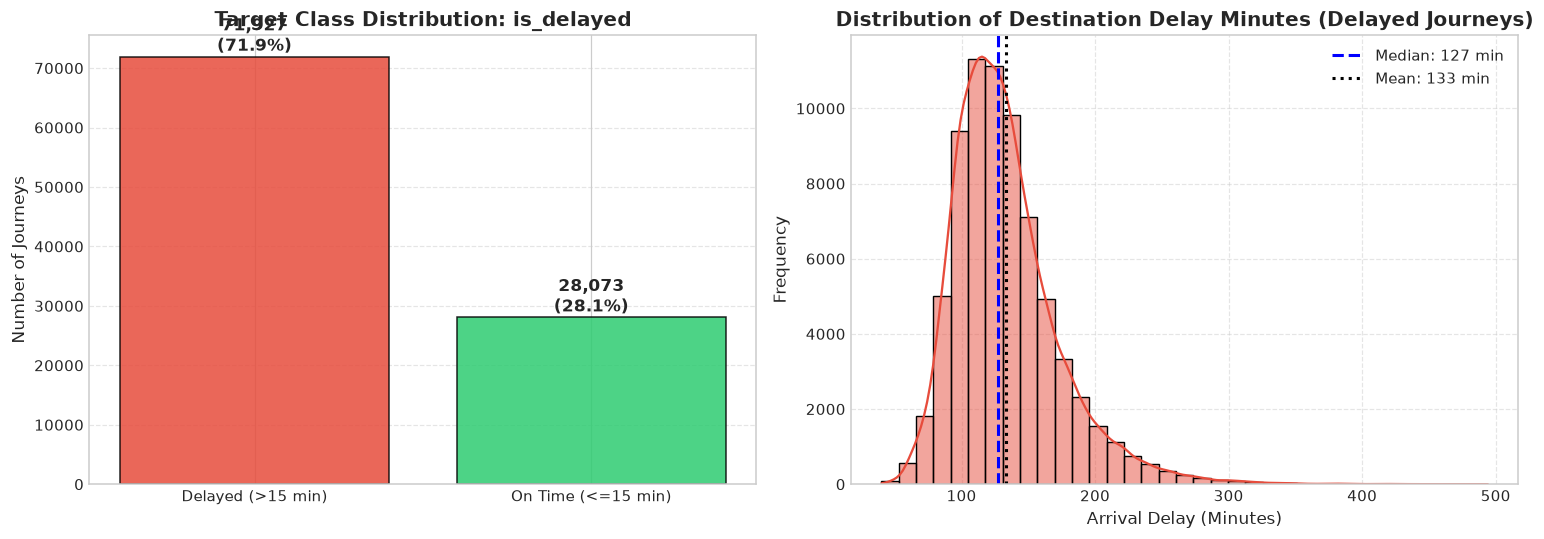

In [5]:
# Plot Target Distribution and Delay Minutes Distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Target Class Proportions
target_counts = df['is_delayed'].value_counts()
labels = ['Delayed (>15 min)', 'On Time (<=15 min)']
colors = ['#e74c3c', '#2ecc71']
axes[0].bar(labels, target_counts.values, color=colors, edgecolor='black', alpha=0.85)
for i, v in enumerate(target_counts.values):
    pct = v / len(df) * 100
    axes[0].text(i, v + 1000, f"{v:,}\n({pct:.1f}%)", ha='center', fontweight='bold', fontsize=11)
axes[0].set_title('Target Class Distribution: is_delayed', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Number of Journeys', fontsize=11)
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

# Delay Minutes Distribution (for delayed trains)
delayed_minutes = df[df['is_delayed'] == 1]['delay_minutes']
sns.histplot(delayed_minutes, bins=35, kde=True, color='#e74c3c', ax=axes[1], edgecolor='black')
axes[1].axvline(delayed_minutes.median(), color='blue', linestyle='--', linewidth=2, label=f'Median: {delayed_minutes.median():.0f} min')
axes[1].axvline(delayed_minutes.mean(), color='black', linestyle=':', linewidth=2, label=f'Mean: {delayed_minutes.mean():.0f} min')
axes[1].set_title('Distribution of Destination Delay Minutes (Delayed Journeys)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Arrival Delay (Minutes)', fontsize=11)
axes[1].set_ylabel('Frequency', fontsize=11)
axes[1].legend(fontsize=10)
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### 5.2 Bivariate Analysis: Delay Rates across Train Categories & Administrative Zones
Evaluating how punctuality varies by train hierarchy (Premier vs Standard) and geographic railway zone.

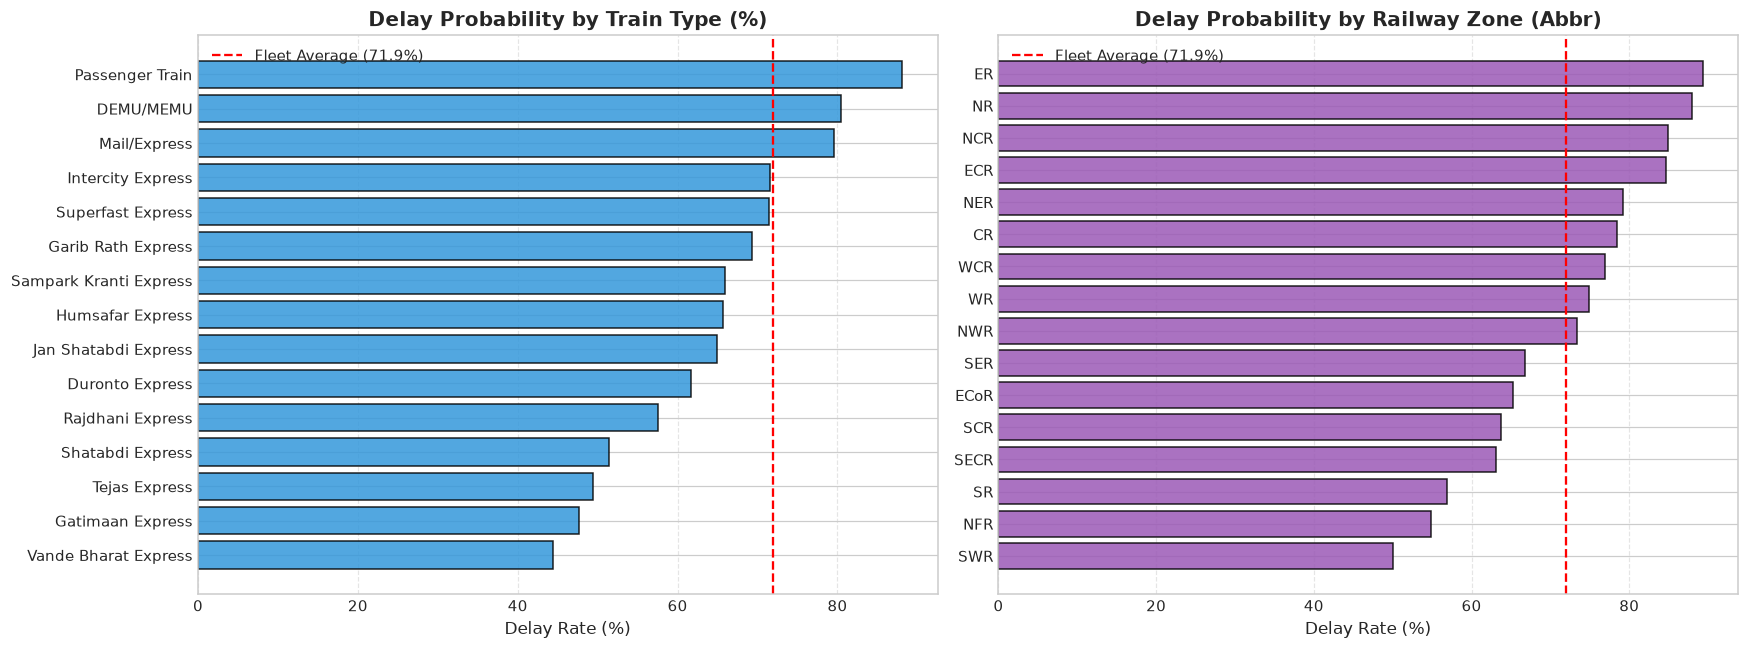

In [6]:
# Delay rate by Train Type and Zone
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Train Type Delay Probability
train_type_delay = df.groupby('train_type')['is_delayed'].agg(['count', 'mean']).sort_values('mean')
train_type_delay = train_type_delay[train_type_delay['count'] >= 500]
axes[0].barh(train_type_delay.index, train_type_delay['mean'] * 100, color='#3498db', edgecolor='black', alpha=0.85)
axes[0].axvline(df['is_delayed'].mean() * 100, color='red', linestyle='--', label=f'Fleet Average ({df["is_delayed"].mean()*100:.1f}%)')
axes[0].set_title('Delay Probability by Train Type (%)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Delay Rate (%)', fontsize=11)
axes[0].legend()
axes[0].grid(axis='x', linestyle='--', alpha=0.5)

# Delay Rate by Railway Zone
zone_delay = df.groupby('zone_abbr')['is_delayed'].agg(['count', 'mean']).sort_values('mean')
axes[1].barh(zone_delay.index, zone_delay['mean'] * 100, color='#9b59b6', edgecolor='black', alpha=0.85)
axes[1].axvline(df['is_delayed'].mean() * 100, color='red', linestyle='--', label=f'Fleet Average ({df["is_delayed"].mean()*100:.1f}%)')
axes[1].set_title('Delay Probability by Railway Zone (Abbr)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Delay Rate (%)', fontsize=11)
axes[1].legend()
axes[1].grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### 5.3 Operational Dynamics: Weather Severity & Late Incoming Rake Cascading
Delays frequently cascade throughout the railway network when an incoming rake from a prior journey arrives behind schedule or when seasonal weather hazards intensify.

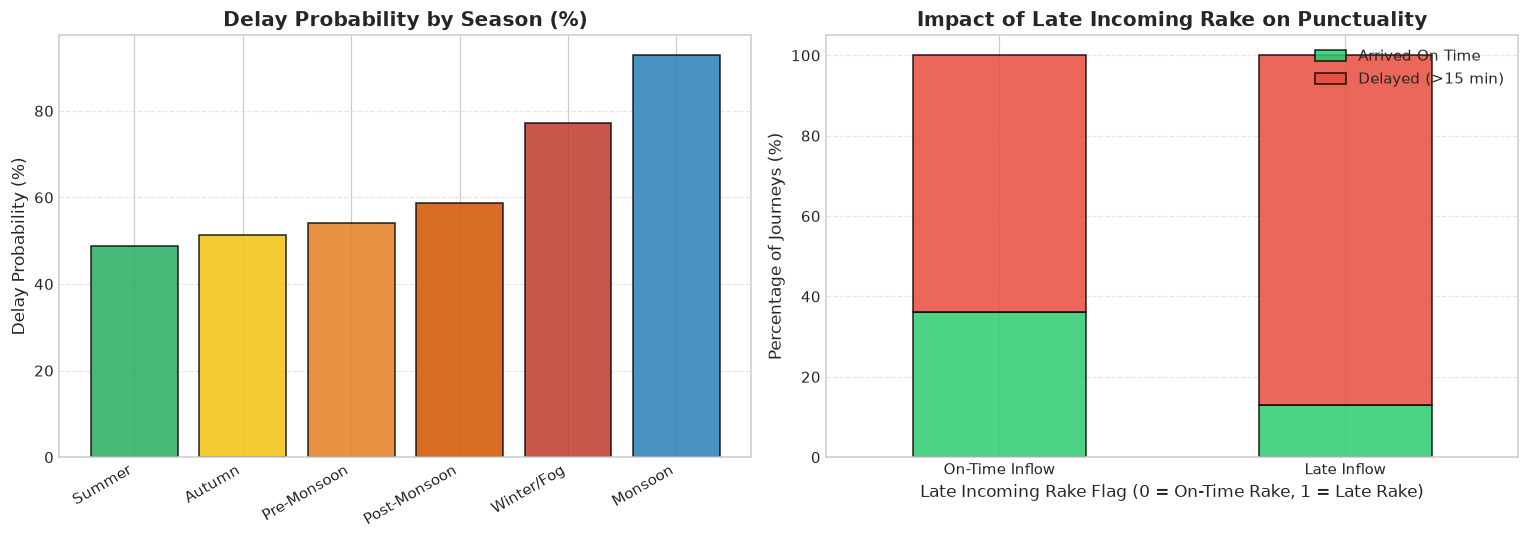

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Season vs Delay Probability
season_delay = df.groupby('season')['is_delayed'].mean().sort_values() * 100
colors_season = ['#27ae60', '#f1c40f', '#e67e22', '#d35400', '#c0392b', '#2980b9']
axes[0].bar(season_delay.index, season_delay.values, color=colors_season, edgecolor='black', alpha=0.85)
axes[0].set_title('Delay Probability by Season (%)', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Delay Probability (%)', fontsize=11)
axes[0].set_xticklabels(season_delay.index, rotation=30, ha='right')
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

# 2. Impact of Late Incoming Rake on Punctuality
rake_impact = df.groupby('late_incoming_rake')['is_delayed'].value_counts(normalize=True).unstack() * 100
rake_impact.plot(kind='bar', stacked=True, color=['#2ecc71', '#e74c3c'], ax=axes[1], edgecolor='black', alpha=0.85)
axes[1].set_title('Impact of Late Incoming Rake on Punctuality', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Late Incoming Rake Flag (0 = On-Time Rake, 1 = Late Rake)', fontsize=11)
axes[1].set_ylabel('Percentage of Journeys (%)', fontsize=11)
axes[1].set_xticklabels(['On-Time Inflow', 'Late Inflow'], rotation=0)
axes[1].legend(['Arrived On Time', 'Delayed (>15 min)'], loc='upper right')
axes[1].grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### 5.4 Primary Root Causes of Delays (Ground Truth Diagnostic)
The training corpus includes the operational attribute `primary_delay_cause`. We analyse this for diagnostic and domain understanding.

> **CRITICAL DATA LEAKAGE NOTICE:**  
> `primary_delay_cause` and `delay_minutes` are labeled `[TRAIN SET ONLY]`. They represent post-trip destination outcome measurements.  
> Using them as model inputs constitutes **Target Leakage**. They are explored strictly during EDA and **excluded from model training**.

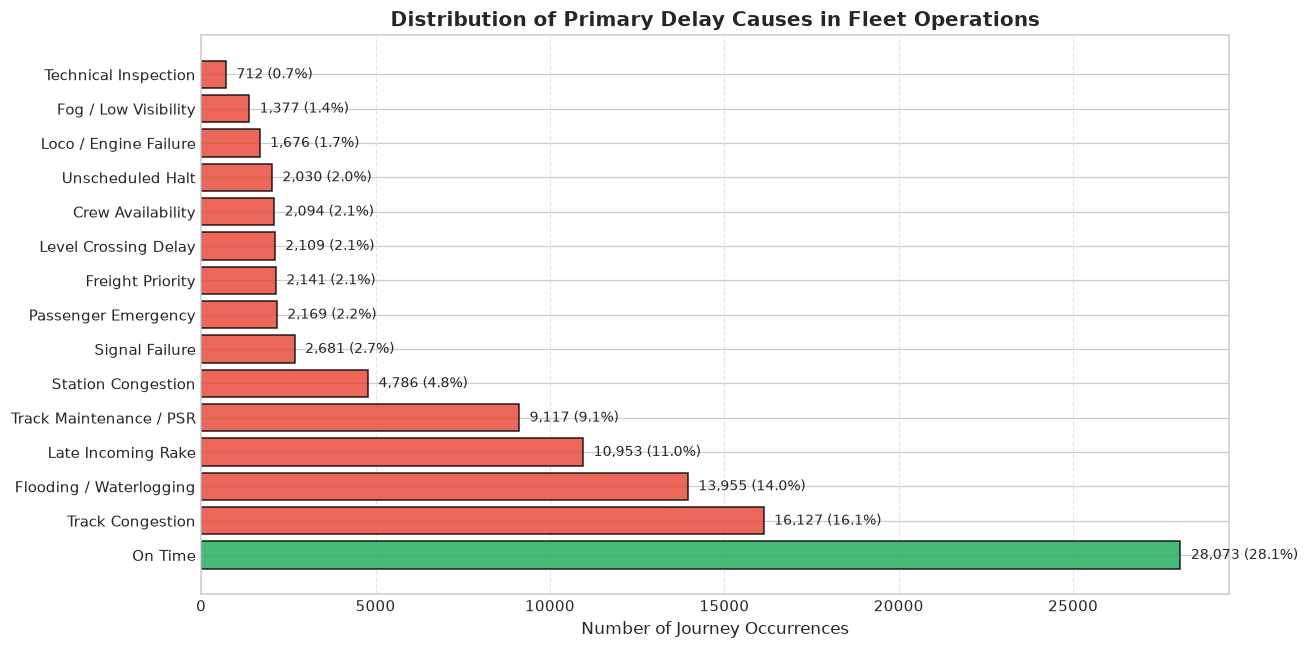

In [8]:
# Distribution of primary delay causes
plt.figure(figsize=(12, 6))
cause_counts = df['primary_delay_cause'].value_counts()
colors = ['#27ae60' if c == 'On Time' else '#e74c3c' for c in cause_counts.index]

plt.barh(cause_counts.index, cause_counts.values, color=colors, edgecolor='black', alpha=0.85)
plt.title('Distribution of Primary Delay Causes in Fleet Operations', fontsize=13, fontweight='bold')
plt.xlabel('Number of Journey Occurrences', fontsize=11)
for i, v in enumerate(cause_counts.values):
    plt.text(v + 300, i, f"{v:,} ({v/len(df)*100:.1f}%)", va='center', fontsize=9)
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### 5.5 Correlation Analysis with Target Variable
Examining linear associations between valid operational features and `is_delayed`.

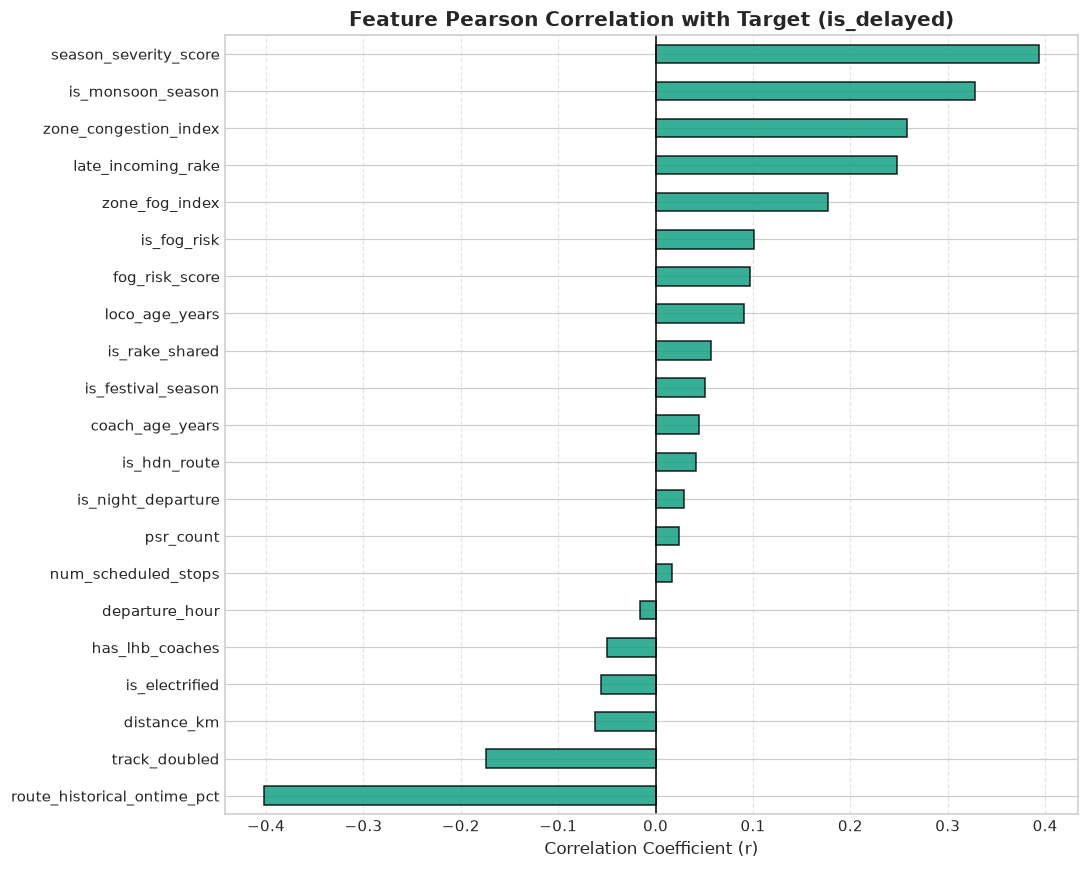

In [9]:
# Compute Pearson correlation with is_delayed excluding target-leaking fields
valid_numeric = [
    'season_severity_score', 'is_monsoon_season', 'zone_congestion_index',
    'late_incoming_rake', 'zone_fog_index', 'is_fog_risk', 'fog_risk_score',
    'loco_age_years', 'is_rake_shared', 'is_festival_season', 'coach_age_years',
    'is_hdn_route', 'is_night_departure', 'psr_count', 'num_scheduled_stops',
    'departure_hour', 'has_lhb_coaches', 'is_electrified', 'distance_km',
    'track_doubled', 'route_historical_ontime_pct', 'is_delayed'
]

corr_matrix = df[valid_numeric].corr()

plt.figure(figsize=(10, 8))
top_corr_features = corr_matrix['is_delayed'].sort_values()
top_corr_features[:-1].plot(kind='barh', color='#16a085', edgecolor='black', alpha=0.85)
plt.title('Feature Pearson Correlation with Target (is_delayed)', fontsize=13, fontweight='bold')
plt.xlabel('Correlation Coefficient (r)', fontsize=11)
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.axvline(0, color='black', linewidth=1)
plt.tight_layout()
plt.show()

## Summary of Key EDA Findings & Strategic Decisions

1. **Target Distribution:**
   - 71.9% of train journeys experienced arrival delays exceeding 15 minutes, while 28.1% arrived on time.
   - Stratified sampling is essential during validation splits to preserve this class balance.
2. **Top Predictive Signals:**
   - `route_historical_ontime_pct` (r = -0.40): Strongest negative predictor; routes with proven punctuality maintain resilience.
   - `season_severity_score` (r = +0.39) & `is_monsoon_season` (r = +0.33): Inclement weather, monsoon track flooding, and waterlogging are massive delay drivers.
   - `zone_congestion_index` (r = +0.26) & `late_incoming_rake` (r = +0.25): High network saturation and turnaround bottlenecks cause delay propagation.
   - `track_doubled` (r = -0.17): Multi-tracking substantially mitigates crossing halts and train overtakes.
3. **Data Quality Actions for Preprocessing (Notebook 2):**
   - **Zero-variance elimination:** Drop `is_overloaded` (constant 0).
   - **ID removal:** Drop `journey_id` (high cardinality random identifier).
   - **Data Leakage Quarantine:** Drop `primary_delay_cause` and `delay_minutes` from model training feature matrices.
   - **Domain Feature Engineering:** Formulate speed efficiency, stop density, weather vulnerability index, and turnaround cascade risks.

---
**Proceed to Notebook 2:** `02_Data_Preprocessing_and_Feature_Engineering.ipynb`